# Аугментации туристических Reels: качественный пилот

Проверяем доступность восьми пользовательских ссылок, свойства медиа и последствия преобразований кадров/аудио. Это исследование пригодности данных для research-трека; моделей и API распознавания здесь нет. Все вычисления выполняются на CPU-сервере, а результаты сохраняются в outputs ноутбука.

Выборка удобства: восемь ссылок от одного участника команды, без случайного отбора из Instagram. Нельзя переносить наблюдения на все Reels или считать их оценкой качества приложения. Неизвестное место не становится подтверждённым POI из-за упоминания в подписи.



In [1]:
import os, json, re, hashlib, random, subprocess, wave, io, math
from pathlib import Path
from datetime import datetime, timezone
from html import escape
from collections import Counter
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")
from PIL import Image, ImageEnhance
import imageio_ffmpeg
import yt_dlp
from IPython.display import display, HTML, Audio

SEED = 205
IDS = [
    "Deo6s-wMczX", "De4IKljoBfq", "DfAKNCvNDX5", "DfQLrCFtOJH",
    "DeaymE_CCu1", "De2M3kBN9Uf", "DfFjeo8oPpC", "De56UsuT0HW",
]
ROOT = Path.cwd()
WORK = Path(os.getenv("REELS_WORKDIR", ROOT / "outputs/reels_augmentations"))
WORK.mkdir(parents=True, exist_ok=True)
FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})


def table(rows):
    if not rows:
        print("Нет записей.")
        return
    keys = list(rows[0])
    display(HTML("<table><tr>" + "".join(f"<th>{escape(str(k))}</th>" for k in keys)
                 + "</tr>" + "".join("<tr>" + "".join(
                     f"<td>{escape(str(r.get(k, '')))}</td>" for k in keys
                 ) + "</tr>" for r in rows) + "</table>"))


def ffmpeg(args):
    p = subprocess.run(
        [FFMPEG, "-hide_banner", "-loglevel", "error", "-nostdin", "-threads", "2",
         *map(str, args)], capture_output=True, text=True,
    )
    if p.returncode:
        raise RuntimeError(p.stderr[-500:])
    return p


def write_json(path, obj):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")


def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


print("Дата UTC:", datetime.now(timezone.utc).isoformat())
print("Ссылок:", len(IDS), "; seed:", SEED)
print("Пакеты:", {p: version(p) for p in ["numpy", "matplotlib", "pillow", "yt-dlp", "imageio-ffmpeg"]})
print("FFmpeg:", imageio_ffmpeg.get_ffmpeg_version())

Дата UTC: 2026-11-03T13:06:28.448164+00:00
Ссылок: 8 ; seed: 205
Пакеты: {'numpy': '2.3.4', 'matplotlib': '3.10.7', 'pillow': '13.0.0', 'yt-dlp': '2026.10.26', 'imageio-ffmpeg': '0.8.0'}
FFmpeg: n9.0.2-17-g2a571b6068-20260930


## 1. Доступность ссылок и исходные данные

Скачиваем только публично доступные потоки без cookies. По умолчанию используется локальный кэш; для первого получения задайте REELS_ALLOW_DOWNLOAD=1. Неудачный запрос сохраняется как ограничение доступа, а не как «плохой» или отсутствующий видеоконтент. Для повтора после ошибки нужен REELS_RETRY_FAILED=1.

Подпись, геометка публикации и показанное место имеют разный смысл. Пустое поле location означает, что extractor не вернул геометку. Секреты, подписанные CDN URL и исходные видео не публикуем.

In [2]:
class QuietLogger:
    def debug(self, msg): pass
    def warning(self, msg): pass
    def error(self, msg): pass


manifest_path = WORK / "media_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {}
allow_download = os.getenv("REELS_ALLOW_DOWNLOAD") == "1"
retry_failed = os.getenv("REELS_RETRY_FAILED") == "1"
options = {
    "quiet": True, "no_warnings": True, "noprogress": True, "logger": QuietLogger(),
    "socket_timeout": 15, "retries": 0, "extractor_retries": 0, "noplaylist": True,
    "ffmpeg_location": FFMPEG, "max_filesize": 30_000_000,
}
for reel_id in IDS:
    previous = manifest.get(reel_id)
    if previous and (previous.get("status") == "ok" or not retry_failed):
        continue
    if not allow_download:
        manifest[reel_id] = {"id": reel_id, "status": "not_downloaded",
                             "error": "Разрешите скачивание или предоставьте локальные медиа."}
        continue
    folder = WORK / reel_id
    folder.mkdir(exist_ok=True)
    row = {"id": reel_id, "source_url": f"https://www.instagram.com/reel/{reel_id}/",
           "retrieved_at_utc": datetime.now(timezone.utc).isoformat()}
    try:
        with yt_dlp.YoutubeDL(options) as dl:
            info = dl.extract_info(row["source_url"], download=False)
        row.update({k: info.get(k) for k in [
            "title", "description", "uploader", "upload_date", "duration", "location",
            "latitude", "longitude",
        ]})
        row["subtitles"] = list((info.get("subtitles") or {}).keys())
        row["streams"] = {}
        for label, selector in [
            ("audio", "bestaudio/best"),
            ("video", "bestvideo[height<=720]/best[height<=720]/bestvideo/best"),
        ]:
            with yt_dlp.YoutubeDL({
                **options, "format": selector, "outtmpl": str(folder / (label + ".%(ext)s"))
            }) as dl:
                item = dl.extract_info(row["source_url"], download=True)
                path = Path(dl.prepare_filename(item))
            if not path.is_file():
                raise RuntimeError("Поток пропущен, возможно превышение лимита размера.")
            row["streams"][label] = {
                "path": path.relative_to(WORK).as_posix(), "bytes": path.stat().st_size,
                "sha256": digest(path),
            }
        row["status"] = "ok"
    except Exception as error:
        row["status"] = "unavailable"
        row["error"] = re.sub(r"https?://\S+", "[URL]", str(error))[:400]
    manifest[reel_id] = row
    write_json(manifest_path, manifest)

table([{"Reel": k, "статус": manifest[k]["status"],
        "аудио, MB": round(manifest[k].get("streams", {}).get("audio", {}).get("bytes", 0)/1e6, 2),
        "видео, MB": round(manifest[k].get("streams", {}).get("video", {}).get("bytes", 0)/1e6, 2),
        "причина недоступности": manifest[k].get("error", "")} for k in IDS])
available = [manifest[k] for k in IDS if manifest[k]["status"] == "ok"]
print("Получено:", len(available), "из", len(IDS))

Reel,статус,"аудио, MB","видео, MB",причина недоступности
Deo6s-wMczX,ok,0.67,3.29,
De4IKljoBfq,ok,0.48,2.96,
DfAKNCvNDX5,ok,0.87,3.26,
DfQLrCFtOJH,ok,0.78,3.21,
DeaymE_CCu1,ok,0.31,1.92,
De2M3kBN9Uf,ok,0.42,2.43,
DfFjeo8oPpC,ok,0.48,3.01,
De56UsuT0HW,ok,0.34,2.5,


Получено: 8 из 8


## 2. Свойства медиа и фиксированный выбор кадров

Выбираем два момента на каждом доступном видео с seed=205 до просмотра преобразований. Читаем длительность видеопотока и сохраняем JPEG. Это временная выборка: наличие достопримечательности или надписи не гарантируется. В текущем опыте сетевое скачивание выполнено через ПК с разрешения пользователя; все вычисления выполняются на сервере.

In [3]:
frames, properties = [], []
for index, row in enumerate(available):
    video_path = WORK / row["streams"]["video"]["path"]
    reader = imageio_ffmpeg.read_frames(str(video_path))
    props = next(reader)
    reader.close()
    duration = float(props["duration"])
    width, height = props["source_size"]
    properties.append({"Reel": row["id"], "длительность, с": round(duration, 2),
                       "ширина": width, "высота": height, "fps": props.get("fps")})
    rng = random.Random(SEED + index)
    for n, fraction in enumerate([rng.uniform(.15, .45), rng.uniform(.55, .85)]):
        timestamp = round(duration * fraction, 3)
        path = WORK / row["id"] / f"frame_{n}_seed{SEED+index}_{timestamp:.3f}.jpg"
        if not path.exists():
            ffmpeg(["-y", "-ss", timestamp, "-i", video_path, "-frames:v", "1", "-q:v", "2", path])
        frames.append({"sample_id": f"{row['id']}_f{n}", "reel_id": row["id"],
                       "timestamp": timestamp, "path": path.relative_to(WORK).as_posix(),
                       "seed": SEED + index})
write_json(WORK / "frame_samples.json", frames)
write_json(WORK / "media_properties.json", properties)
table(properties)
print("Выбрано исходных кадров:", len(frames))

Reel,"длительность, с",ширина,высота,fps
Deo6s-wMczX,88.93,360,640,30.0
De4IKljoBfq,52.13,360,640,30.0
DfAKNCvNDX5,102.13,360,640,30.0
DfQLrCFtOJH,93.37,360,640,30.0
DeaymE_CCu1,37.93,360,640,30.0
De2M3kBN9Uf,52.63,360,640,30.0
DfFjeo8oPpC,64.77,360,640,30.0
De56UsuT0HW,41.7,360,640,30.0


Выбрано исходных кадров: 16


### Контактный лист оригиналов

Он нужен для проверки состава выборки и ручного чтения надписей. Два кадра одного ролика не являются независимыми видео. Полная ручная разметка показанных мест отсутствует; неизвестные места не угадываем.

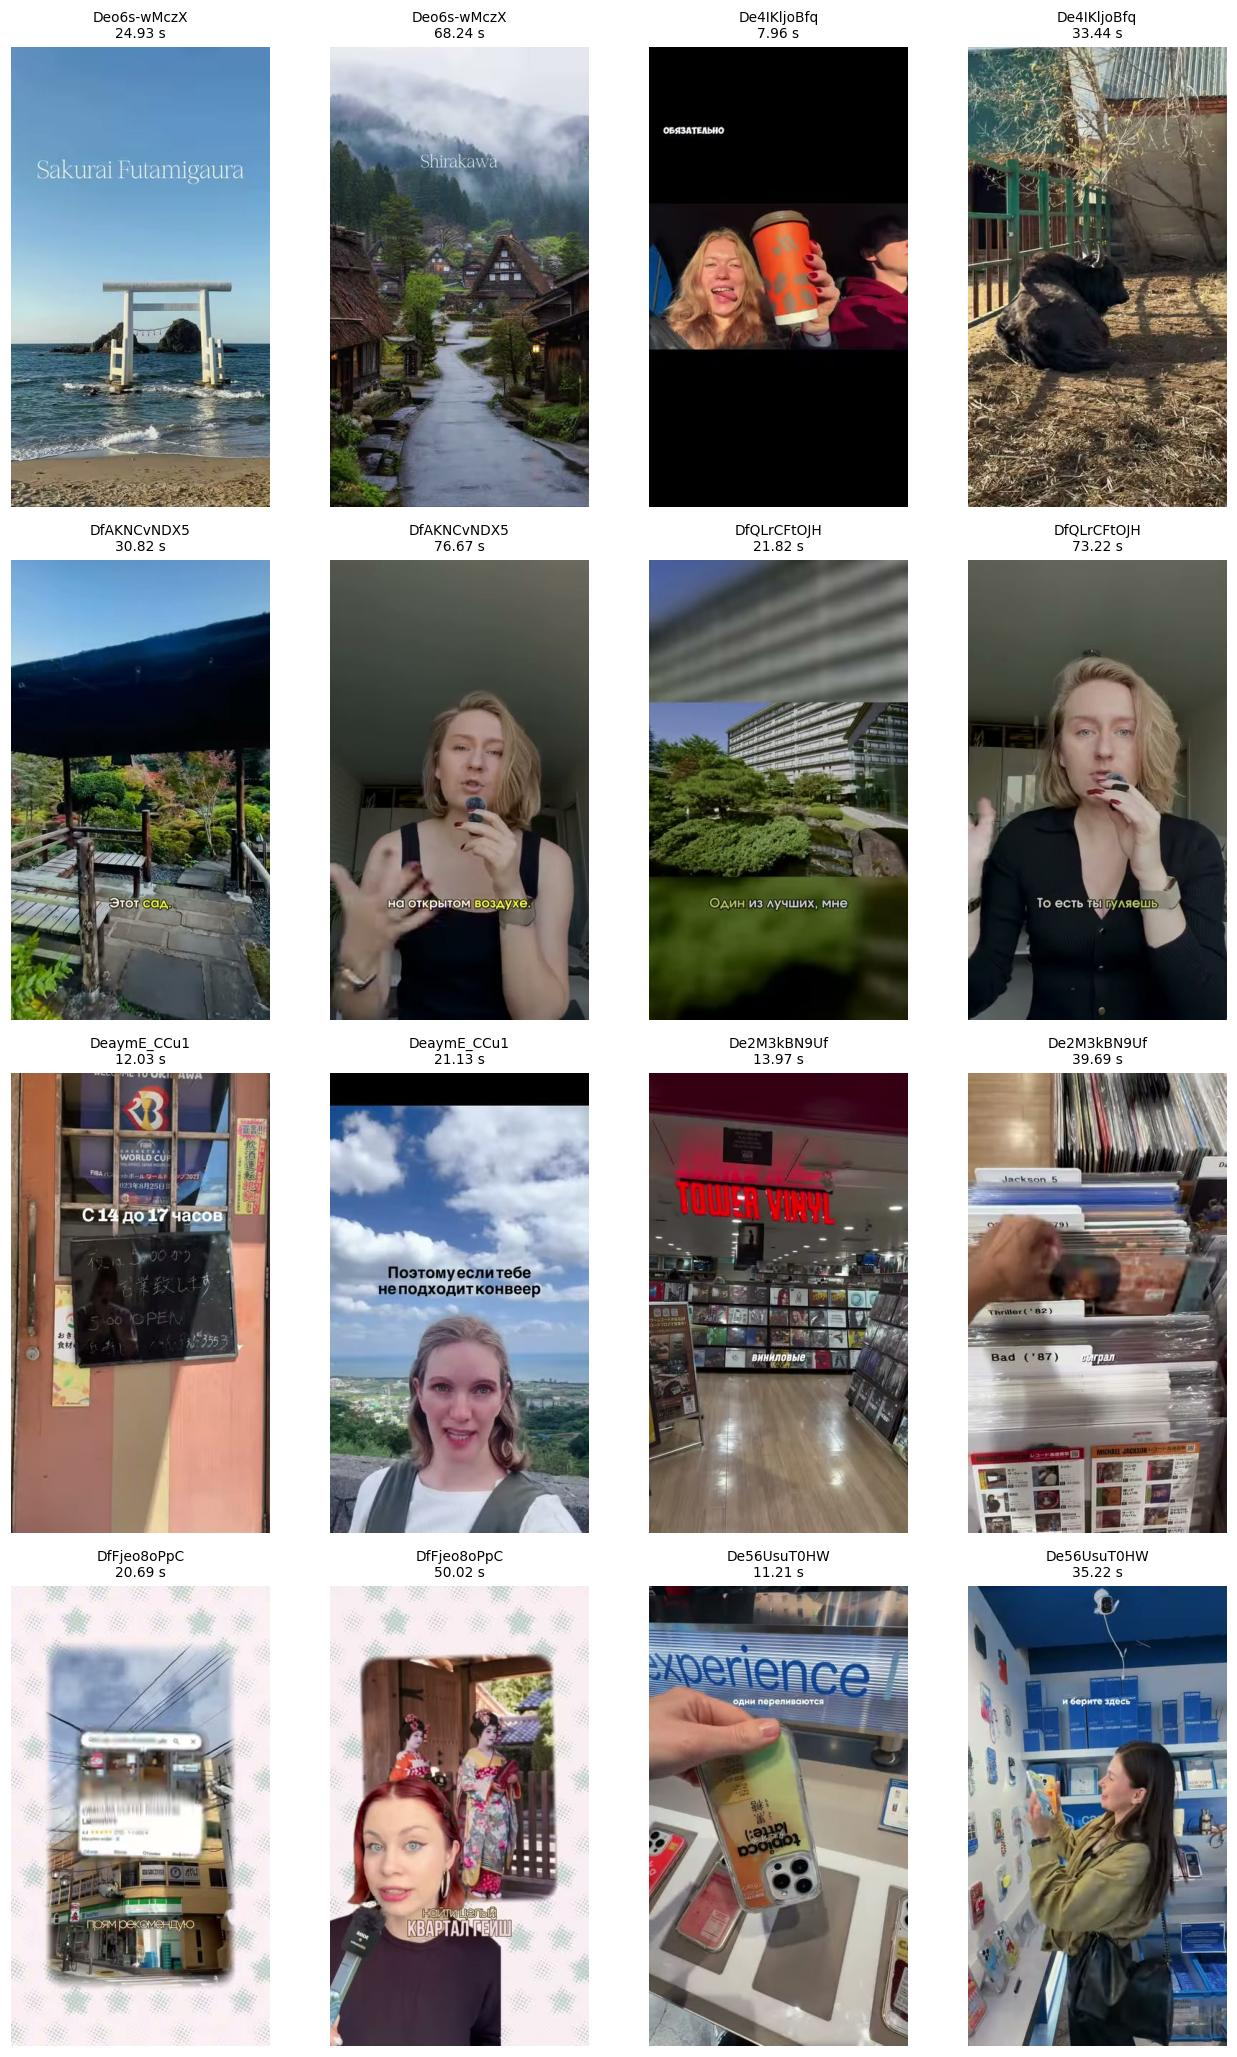

In [4]:
if frames:
    cols = 4
    rows = math.ceil(len(frames) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 4.7), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, frame in zip(axes.flat, frames):
        ax.imshow(Image.open(WORK / frame["path"]))
        ax.set_title(f"{frame['reel_id']}\n{frame['timestamp']:.2f} s", fontsize=9)
    fig.tight_layout()
    fig.savefig(WORK / "original_frames.jpg", dpi=150)
    plt.show()
else:
    print("Нет доступного видео; аугментации не выполняются.")

## 3. Аугментации кадров по одному фактору

Для каждого выбранного кадра проверяем половинное разрешение, JPEG quality=40 и яркость ×0.75. Координаты и исходные таймкоды остаются прежними. Уменьшенные изображения для сопоставления показываем в том же экранном размере; это не восстановление потерянных букв.

PSNR считается после приведения к исходным размерам и описывает только пиксельное различие. Он не измеряет читаемость, точность OCR или сохранность географического признака.

In [5]:
image_rows = []
for frame in frames:
    source = Image.open(WORK / frame["path"]).convert("RGB")
    folder = WORK / frame["reel_id"]
    variants = {
        "half_resolution": source.resize((max(1, source.width//2), max(1, source.height//2)), Image.Resampling.LANCZOS),
        "jpeg_q40": source.copy(),
        "brightness_075": ImageEnhance.Brightness(source).enhance(.75),
    }
    for name, image in variants.items():
        path = folder / (frame["sample_id"] + "_" + name + ".jpg")
        image.save(path, quality=40 if name == "jpeg_q40" else 95)
        decoded = Image.open(path).convert("RGB")
        restored = decoded.resize(source.size, Image.Resampling.LANCZOS)
        mse = float(np.mean((np.asarray(source, dtype=float) - np.asarray(restored, dtype=float))**2))
        image_rows.append({
            "sample_id": frame["sample_id"], "reel_id": frame["reel_id"],
            "timestamp": frame["timestamp"], "transform": name,
            "path": path.relative_to(WORK).as_posix(),
            "source_size": list(source.size), "output_size": list(decoded.size),
            "bytes": path.stat().st_size, "source_bytes": (WORK/frame["path"]).stat().st_size,
            "psnr_db": round(10*math.log10(255**2/mse), 2) if mse else None,
            "seed": frame["seed"],
        })
write_json(WORK / "image_metrics.json", image_rows)
table([{"вид": name, "примеров": len(group),
        "медианный размер, KB": round(float(np.median([r["bytes"] for r in group]))/1000, 1),
        "медианный PSNR, dB": round(float(np.median([r["psnr_db"] for r in group if r["psnr_db"] is not None])), 2)}
       for name in ["half_resolution", "jpeg_q40", "brightness_075"]
       if (group := [r for r in image_rows if r["transform"] == name])])
print("Преобразованных кадров:", len(image_rows))

вид,примеров,"медианный размер, KB","медианный PSNR, dB"
half_resolution,16,25.7,30.44
jpeg_q40,16,20.5,33.3
brightness_075,16,64.8,18.4


Преобразованных кадров: 48


### Сопоставление с оригиналом

Для первого кадра каждого ролика показываем оригинал и три преобразования. Полные данные по обоим выбранным кадрам записаны в image_metrics.json. Сравнивать нужно одинаковые надписи и детали, а не угадывать место по подписи публикации.

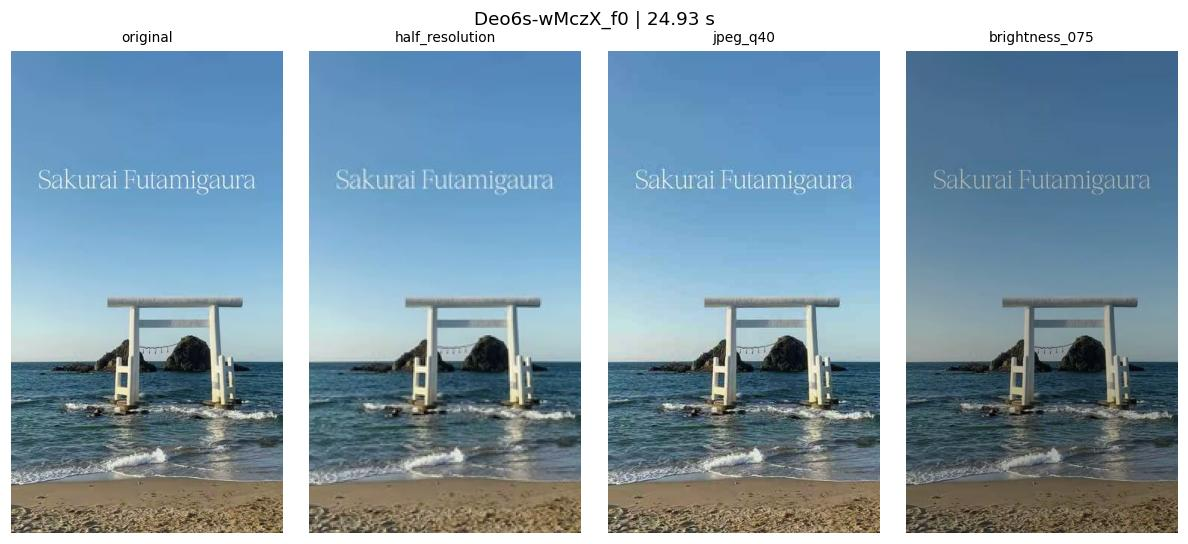

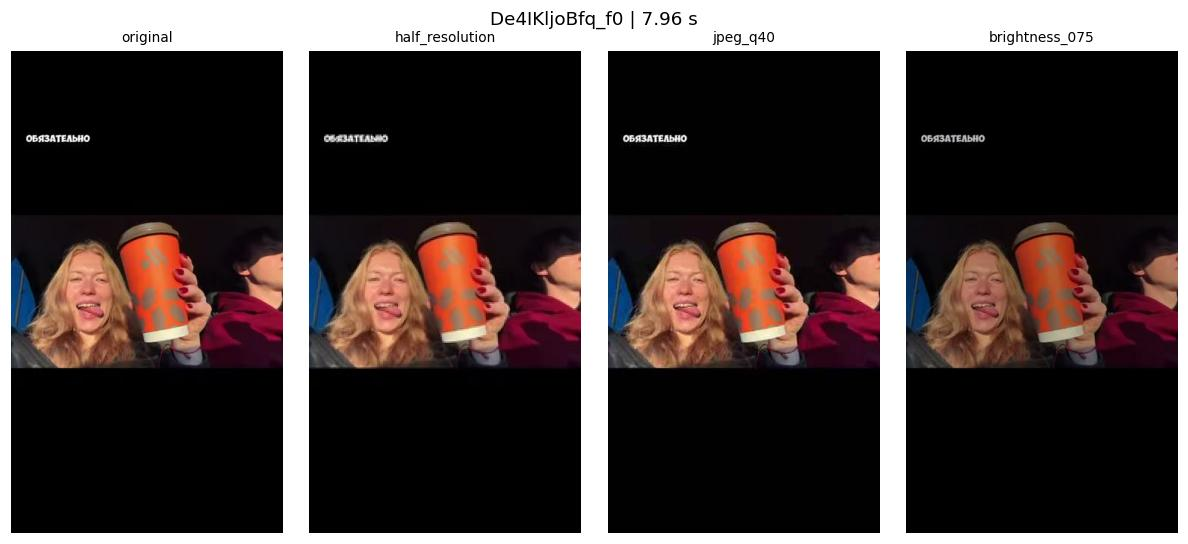

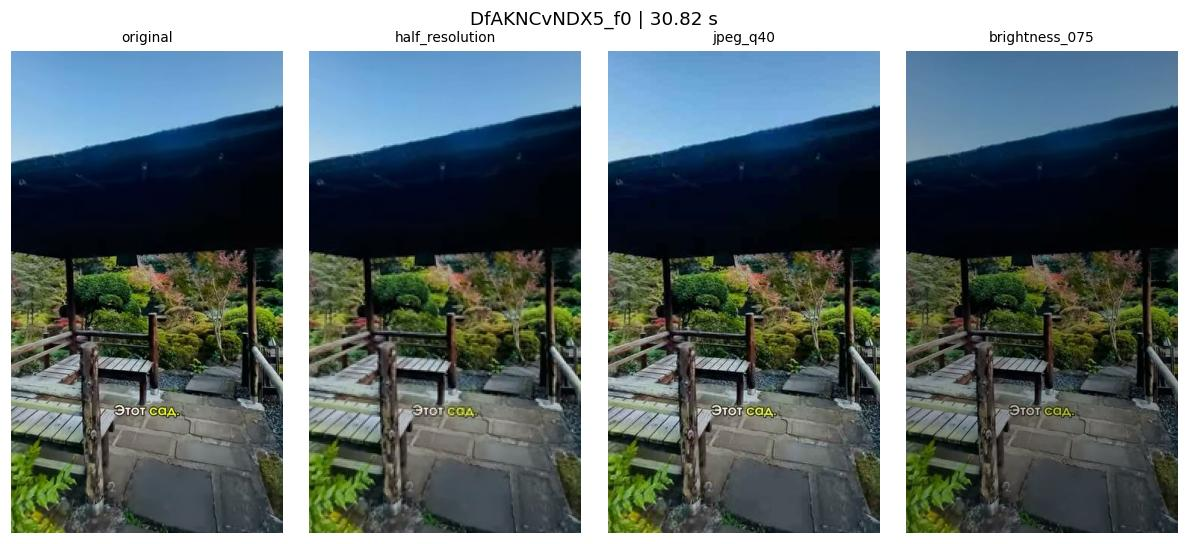

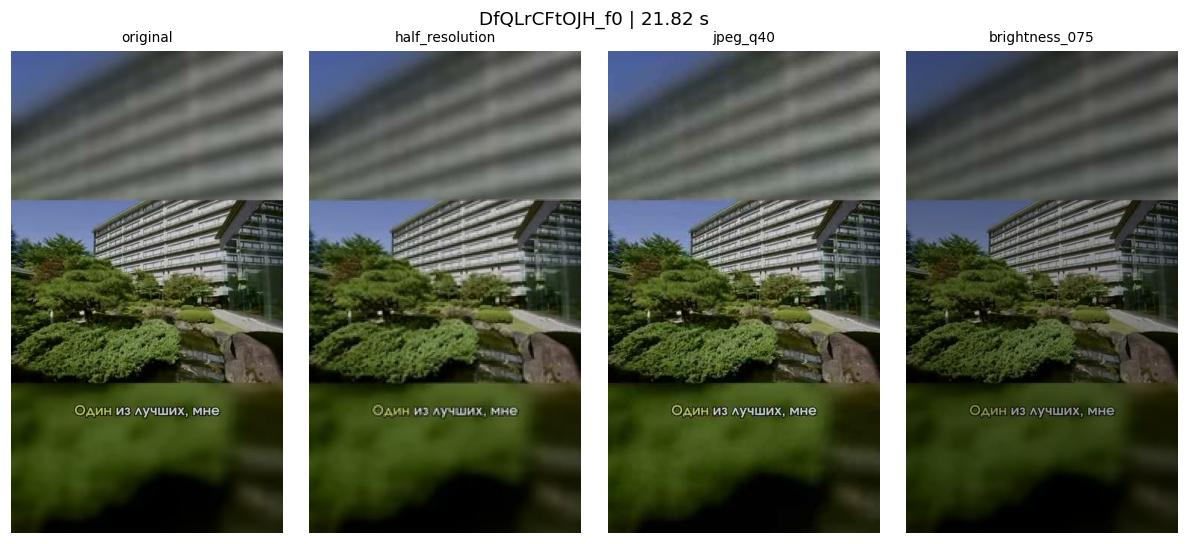

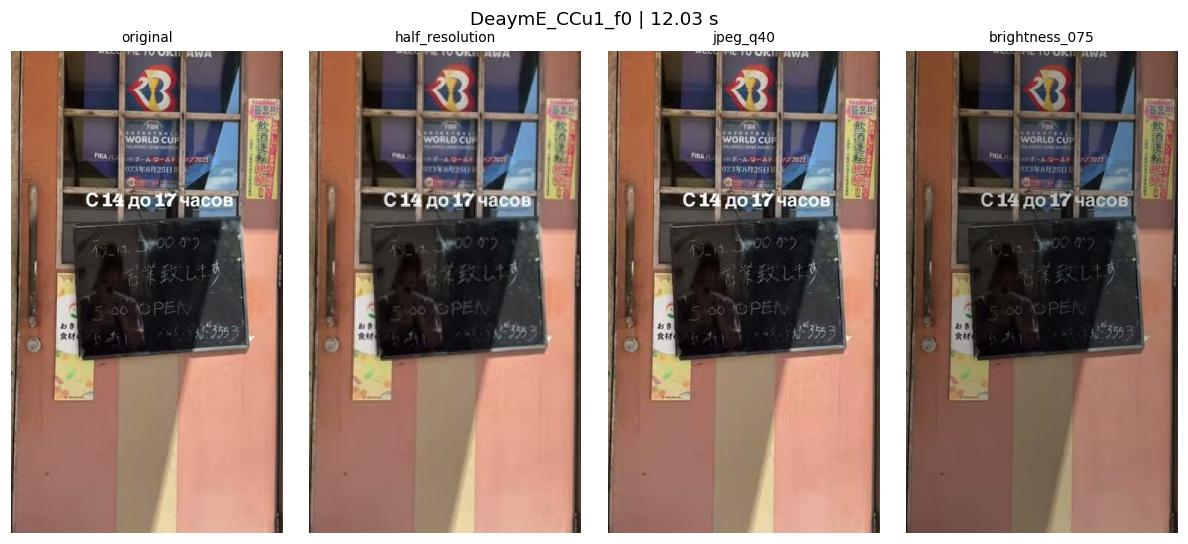

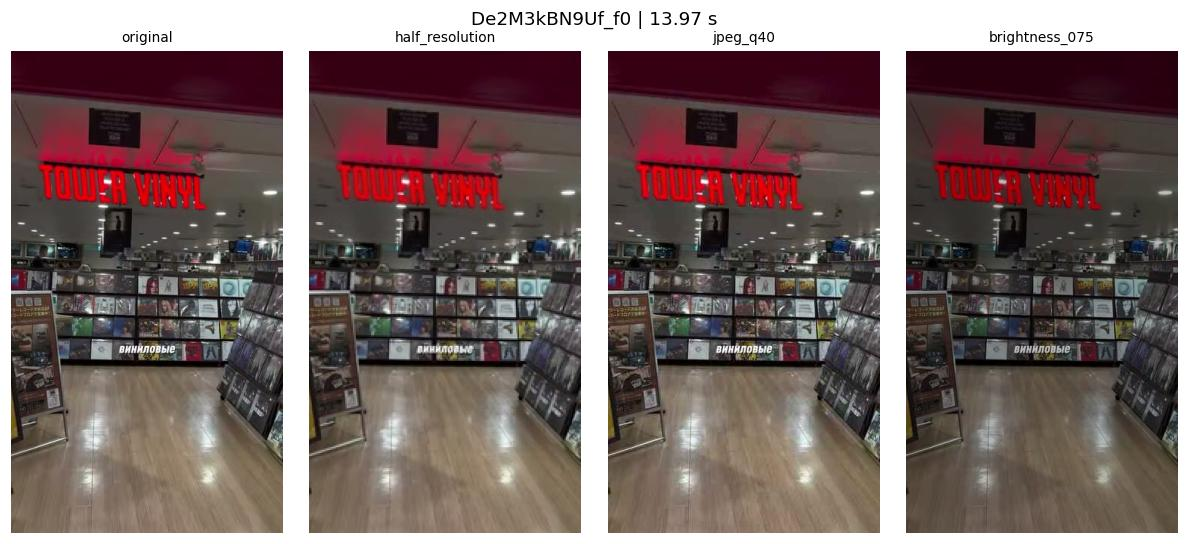

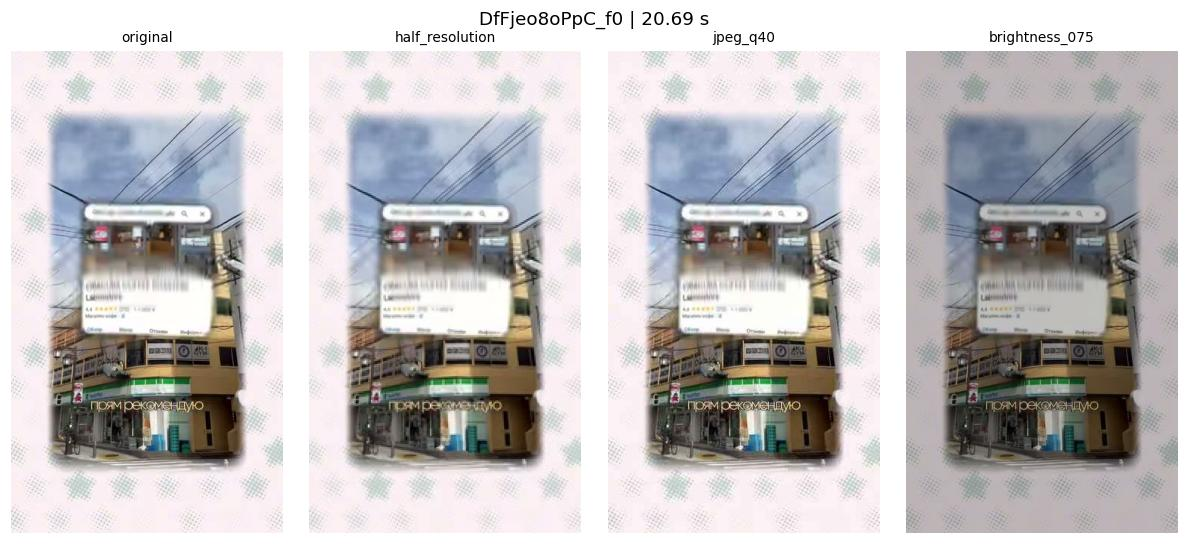

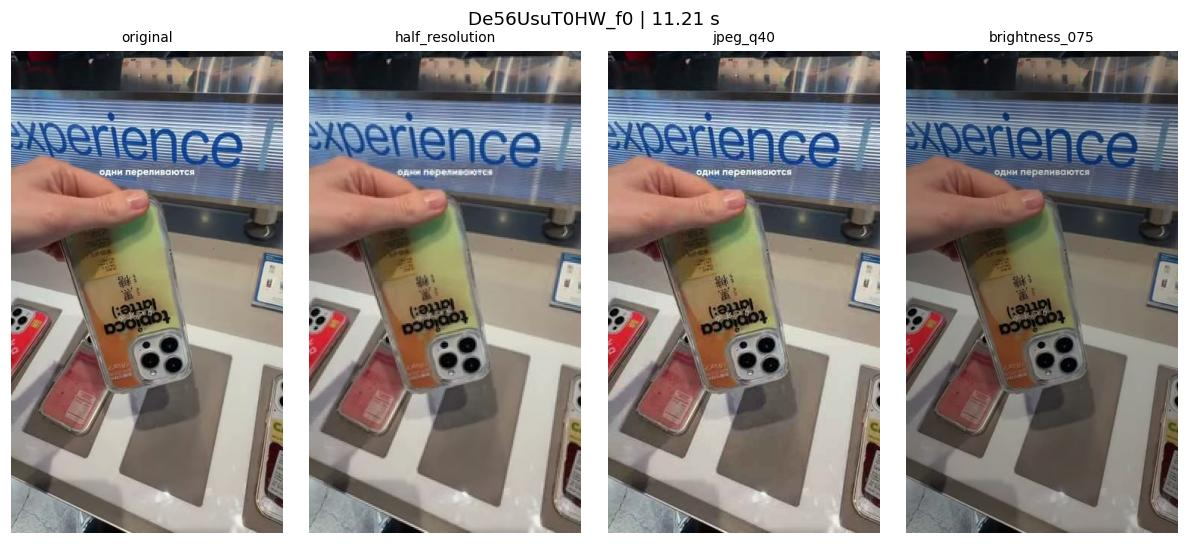

In [6]:
for frame in frames[::2]:
    fig, axes = plt.subplots(1, 4, figsize=(11, 5))
    paths = [("original", frame["path"])] + [
        (r["transform"], r["path"]) for r in image_rows if r["sample_id"] == frame["sample_id"]
    ]
    for ax, (label, path) in zip(axes, paths):
        ax.imshow(Image.open(WORK/path))
        ax.set_title(label, fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{frame['sample_id']} | {frame['timestamp']:.2f} s")
    fig.tight_layout()
    fig.savefig(WORK / (frame["sample_id"] + "_comparison.jpg"), dpi=140)
    plt.show()

## 4. Аудио: контролируемые преобразования коротких фрагментов

Берём первые три доступных ролика в исходном порядке списка, по одному фрагменту до 6 секунд с 30% длительности. Выбор не основан на результатах распознавания или прослушивания. Фрагменты могут содержать музыку, речь или их смесь; они используются как иллюстрации преобразований.

Базовая предобработка: PCM 16 кГц mono, общий peak=0.5 для запаса по уровню. Затем отдельно добавляем белый шум с SNR=20 dB, выполняем AAC 64 kbit/s и atempo=1.05 без изменения высоты тона. Таймкоды ускоренного фрагмента переводятся как t/1.05 относительно его начала.

In [7]:
def read_wave(path):
    with wave.open(str(path), "rb") as stream:
        assert stream.getnchannels() == 1 and stream.getsampwidth() == 2
        rate = stream.getframerate()
        data = np.frombuffer(stream.readframes(stream.getnframes()), dtype="<i2").astype(float)/32768
    return rate, data


def save_wave(path, rate, data):
    if len(data) and np.max(np.abs(data)) >= 1:
        raise ValueError("Сигнал выйдет за PCM-диапазон.")
    with wave.open(str(path), "wb") as stream:
        stream.setnchannels(1)
        stream.setsampwidth(2)
        stream.setframerate(rate)
        stream.writeframes(np.round(data*32767).astype("<i2").tobytes())


audio_rows, audio_paths = [], {}
audio_ids = [row["id"] for row in available[:3]]
for index, reel_id in enumerate(audio_ids):
    row = manifest[reel_id]
    folder = WORK / reel_id
    duration = next(p["длительность, с"] for p in properties if p["Reel"] == reel_id)
    start = round(min(duration*.30, max(0, duration-6)), 3)
    original = folder / "audio_excerpt.wav"
    ffmpeg(["-y", "-ss", start, "-i", WORK/row["streams"]["audio"]["path"],
            "-t", "6", "-map", "0:a:0", "-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", original])
    rate, clean = read_wave(original)
    peak = float(np.max(np.abs(clean))) if len(clean) else 0
    if peak < 1e-8:
        print(reel_id, "тишина; звуковые аугментации неприменимы.")
        continue
    clean = clean * (.5/peak)
    save_wave(original, rate, clean)
    rng = np.random.default_rng(SEED+index)
    noise = rng.normal(size=len(clean))
    noise *= np.sqrt(np.mean(clean**2))/np.sqrt(np.mean(noise**2)) / 10
    noisy = folder/"audio_noise_20db.wav"
    save_wave(noisy, rate, clean+noise)
    aac = folder/"audio_aac64.m4a"
    aac_wave = folder/"audio_aac64.wav"
    ffmpeg(["-y", "-i", original, "-c:a", "aac", "-b:a", "64k", aac])
    ffmpeg(["-y", "-i", aac, "-ar", rate, "-ac", "1", "-c:a", "pcm_s16le", aac_wave])
    tempo = folder/"audio_tempo105.wav"
    ffmpeg(["-y", "-i", original, "-af", "atempo=1.05", "-c:a", "pcm_s16le", tempo])
    variants = {"original": original, "noise_20db": noisy, "aac64_decoded": aac_wave, "tempo105": tempo}
    audio_paths[reel_id] = {k: p.relative_to(WORK).as_posix() for k, p in variants.items()}
    for name, path in variants.items():
        sr, signal = read_wave(path)
        audio_rows.append({
            "reel_id": reel_id, "transform": name, "source_start": start,
            "duration_s": len(signal)/sr, "sample_rate": sr, "bytes": path.stat().st_size,
            "peak": round(float(np.max(np.abs(signal))), 5),
            "rms_dbfs": round(20*np.log10(max(1e-12, np.sqrt(np.mean(signal**2)))), 2),
            "clipped_samples": int(np.sum(np.abs(signal) >= 32767/32768)),
            "snr_db": round(float(10*np.log10(np.mean(clean**2)/np.mean((signal-clean)**2))), 2)
                      if name == "noise_20db" else None,
            "encoded_aac_bytes": aac.stat().st_size if name == "aac64_decoded" else None,
            "path": path.relative_to(WORK).as_posix(),
        })
write_json(WORK/"audio_metrics.json", audio_rows)
table([{k: r[k] for k in ["reel_id", "transform", "duration_s", "peak", "clipped_samples", "snr_db"]}
       for r in audio_rows])
print("Исходных аудиофрагментов:", len(audio_paths))
print("AAC-байты относятся к сжатому файлу, bytes у декодированного варианта — к WAV.")

reel_id,transform,duration_s,peak,clipped_samples,snr_db
Deo6s-wMczX,original,6.0,0.5,0,None
Deo6s-wMczX,noise_20db,6.0,0.51791,0,20.0
Deo6s-wMczX,aac64_decoded,6.0,0.50781,0,None
Deo6s-wMczX,tempo105,5.72625,0.49805,0,None
De4IKljoBfq,original,6.0,0.5,0,None
De4IKljoBfq,noise_20db,6.0,0.52902,0,20.0
De4IKljoBfq,aac64_decoded,6.0,0.49881,0,None
De4IKljoBfq,tempo105,5.711625,0.49924,0,None
DfAKNCvNDX5,original,6.0,0.5,0,None
DfAKNCvNDX5,noise_20db,6.0,0.50119,0,20.0


Исходных аудиофрагментов: 3
AAC-байты относятся к сжатому файлу, bytes у декодированного варианта — к WAV.


### Аудиосравнения

Ниже встроены короткие исходные и преобразованные фрагменты. Таблица выше показывает длительность, уровни сигнала и заданное отношение сигнал/шум. Каждое преобразование применяется отдельно.

In [8]:
for reel_id, variants in audio_paths.items():
    display(HTML(f"<b>{escape(reel_id)}</b>"))
    for name, path in variants.items():
        print(name)
        display(Audio(filename=str(WORK/path), normalize=False))
print("Подготовлено аудиосравнений:", len(audio_paths))


original


noise_20db


aac64_decoded


tempo105


original


noise_20db


... (3 outputs left out)

noise_20db


aac64_decoded


tempo105


Подготовлено аудиосравнений: 3


## 5. Пример преобразования, которое теряет важную информацию

На первом кадре первого ролика надпись «Sakurai Futamigaura» находится в верхней части. Обрезаем верхние 45% кадра и смотрим, сохранилось ли это свидетельство. Такой вариант показываем как отрицательный пример и не объявляем корректной аугментацией с сохранением исходной информации.

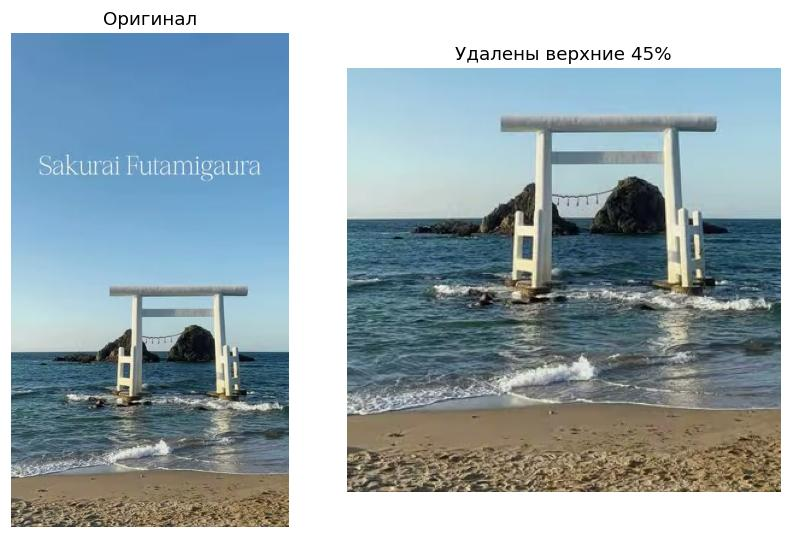

Название в верхней части удалено; метку наличия этой надписи сохранять нельзя.


In [9]:
negative_crop = None
if frames:
    frame = frames[0]
    original = Image.open(WORK/frame["path"]).convert("RGB")
    crop = original.crop((0, int(original.height*.45), original.width, original.height))
    crop_path = WORK/"negative_crop.jpg"
    crop.save(crop_path, quality=95)
    fig, axes = plt.subplots(1, 2, figsize=(8, 5))
    for ax, image, title in zip(axes, [original, crop], ["Оригинал", "Удалены верхние 45%"]):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    negative_crop = {"sample_id": frame["sample_id"], "transform": "crop_top45",
                     "lost_evidence": "надпись Sakurai Futamigaura",
                     "suitable_for_same_evidence_label": False}
    write_json(WORK/"negative_crop_review.json", negative_crop)
    print("Название в верхней части удалено; метку наличия этой надписи сохранять нельзя.")

## 6. Проверки и визуальные наблюдения

Ниже сохранена визуальная проверка трёх показанных сравнений: крупное название над морем, вывеска TOWER VINYL и русская фраза в смонтированном кадре. Проверены именно эти надписи, а не правильность POI. Выбор примеров целевой и не репрезентативный; остальные варианты остаются без ручной оценки.

При половинном разрешении буквы и детали заметно смягчаются, но выбранные крупные надписи ещё читаются. На кадре с карточкой места её мелкий текст уже неразборчив в оригинале: это нельзя приписывать аугментации. Второе независимое ревью не проводилось.

In [10]:
review_targets = {
    "Deo6s-wMczX_f0": ("Sakurai Futamigaura", "Крупное имя читается; форма ворот сохраняется."),
    "De2M3kBN9Uf_f0": ("TOWER VINYL", "Вывеска читается; мелкие обложки не оценивались."),
    "DfFjeo8oPpC_f0": ("Прям рекомендую", "Мелкая карточка места неразборчива уже в оригинале."),
}
reference_sources = {'Deo6s-wMczX': '61f3c0a75081add7379d6014078e1e789a35b95df13ca3a723da03e42e74146b', 'De2M3kBN9Uf': 'e97c086e65e13590550746b5041a387b6434d76bfedfba1397c9adb32231d511', 'DfFjeo8oPpC': 'c2ef1c70b75fd8003610f21156459e752786683039284cb146a8a2cd046607c6'}
reference_times = {"Deo6s-wMczX_f0": 24.93, "De2M3kBN9Uf_f0": 13.97, "DfFjeo8oPpC_f0": 20.69}
visual_review = []
for row in image_rows:
    checked = (row["sample_id"] in review_targets and SEED == 205
               and round(row["timestamp"], 2) == reference_times.get(row["sample_id"])
               and manifest[row["reel_id"]]["streams"]["video"]["sha256"] == reference_sources.get(row["reel_id"]))
    target, comment = review_targets.get(row["sample_id"], ("", ""))
    visual_review.append({
        "sample_id": row["sample_id"], "transform": row["transform"],
        "review_status": "визуально проверено" if checked else "не проверено",
        "text_to_check": target or None,
        "selected_text_readable": True if checked else None,
        "comment": comment if checked else "",
    })
write_json(WORK/"visual_review.json", visual_review)
assert len(frames) == 2*len(available)
assert len(image_rows) == 3*len(frames)
assert all(0 <= f["timestamp"] < next(p["длительность, с"] for p in properties
                                   if p["Reel"] == f["reel_id"]) + .01 for f in frames)
assert all(r["clipped_samples"] == 0 for r in audio_rows)
assert all(abs(r["snr_db"]-20) < .1 for r in audio_rows if r["snr_db"] is not None)
for row in available:
    for stream in row["streams"].values():
        assert digest(WORK/stream["path"]) == stream["sha256"]
summary = {
    "reels_received": len(available), "reels_requested": len(IDS),
    "source_frames": len(frames), "augmented_frames": len(image_rows),
    "visual_checks": sum(r["review_status"] == "визуально проверено" for r in visual_review),
    "source_audio_excerpts": len(audio_paths),
    "audio_variants_including_originals": len(audio_rows),
    "negative_crop": negative_crop,
    "models_used": False,
    "sample_selection": "convenience sample; fixed seed; two frames per video",
}
write_json(WORK/"summary.json", summary)
table([{"показатель": k, "значение": v} for k, v in summary.items()
       if not isinstance(v, dict)])
table([r for r in visual_review if r["review_status"] == "визуально проверено"])
print("Проверки размеров, таймкодов, SHA-256, clipping и заданного SNR пройдены.")

показатель,значение
reels_received,8
reels_requested,8
source_frames,16
augmented_frames,48
visual_checks,9
source_audio_excerpts,3
audio_variants_including_originals,12
models_used,False
sample_selection,convenience sample; fixed seed; two frames per video


sample_id,transform,review_status,text_to_check,selected_text_readable,comment
Deo6s-wMczX_f0,half_resolution,визуально проверено,Sakurai Futamigaura,True,Крупное имя читается; форма ворот сохраняется.
Deo6s-wMczX_f0,jpeg_q40,визуально проверено,Sakurai Futamigaura,True,Крупное имя читается; форма ворот сохраняется.
Deo6s-wMczX_f0,brightness_075,визуально проверено,Sakurai Futamigaura,True,Крупное имя читается; форма ворот сохраняется.
De2M3kBN9Uf_f0,half_resolution,визуально проверено,TOWER VINYL,True,Вывеска читается; мелкие обложки не оценивались.
De2M3kBN9Uf_f0,jpeg_q40,визуально проверено,TOWER VINYL,True,Вывеска читается; мелкие обложки не оценивались.
De2M3kBN9Uf_f0,brightness_075,визуально проверено,TOWER VINYL,True,Вывеска читается; мелкие обложки не оценивались.
DfFjeo8oPpC_f0,half_resolution,визуально проверено,Прям рекомендую,True,Мелкая карточка места неразборчива уже в оригинале.
DfFjeo8oPpC_f0,jpeg_q40,визуально проверено,Прям рекомендую,True,Мелкая карточка места неразборчива уже в оригинале.
DfFjeo8oPpC_f0,brightness_075,визуально проверено,Прям рекомендую,True,Мелкая карточка места неразборчива уже в оригинале.


Проверки размеров, таймкодов, SHA-256, clipping и заданного SNR пройдены.


## 7. Выводы для проекта

Публичные ссылки доступны с ПК, но прямое получение на сервере завершилось тайм-аутами. Для продукта потребуется надёжный способ загрузки и понятная обработка недоступности.

Уменьшение разрешения теряет мелкие детали; JPEG-сжатие создаёт артефакты вокруг букв; затемнение сохраняет геометрию, но ослабляет видимость тёмных областей. В трёх визуально проверенных примерах выбранные крупные надписи сохранились. Обрезка удалила название места при сохранении части сцены: после неё прежняя метка наличия надписи становится неверной.

Для аудио подготовлены шум SNR=20 dB, AAC 64 kbit/s и ускорение ×1.05. Проверены длительность, уровни и отсутствие насыщенных PCM-сэмплов. При ускорении временную разметку нужно масштабировать; нормализация в 16 кГц mono относится к предобработке.

Все варианты одного ролика должны оставаться в одном split. Этот качественный пилот помогает выбрать допустимые преобразования и выявить ограничения данных; он основан на восьми пользовательских ссылках и коррелированных кадрах, а не на репрезентативной выборке.